# Quickstart in Python

This notebook mirrors the current README quickstart for `Accio_967b7813_raw_merged`, but uses the Python APIs behind the CLI commands.

1. Download the public stork study subset.
2. Extract point features.
3. Pack DeepSSF shards.
4. Run the lite benchmark.

After download it plots all stork tracks on a map. After bench it plots normalized energy scores and a few spatial prediction examples for the completed stork runs.


In [1]:
import os

import movebench.paths as paths

REPO_ROOT = paths.repo_root()
os.chdir(REPO_ROOT)

STUDY_ID = "Accio_967b7813_raw_merged"
LAYERS_CONFIG = str(REPO_ROOT / "configs/layers/lite_12h_12h.yaml")
SAMPLER_CONFIG = str(REPO_ROOT / "configs/samplers/issf_defaults.yaml")
TIMESCALE_KEY = "12h"
EXPERIMENT_MODULE = "experiments/lite.py"
DOWNLOAD_WORKERS = 4
EXTRACT_WORKERS = 4
PACK_WORKERS = 4

RUNS_ROOT = REPO_ROOT / "results" / "bench" / "runs"
TIMESCALE_ORDER = ["1h", "12h", "1d", "7d"]
SPLIT_ORDER = ["test_temporal", "test_individual"]
PLOT_METHODS = ["baseline_randomwalk", "issf_linear", "issf_mlp", "deepssf", "moveformer"]
NORMALIZE_BY = "baseline_nomove"


## 1. Download

This is the Python equivalent of:

```bash
movebench download --studies Accio_967b7813_raw_merged --layers-config configs/layers/lite_12h_12h.yaml --n-workers 4
```


In [ ]:
from movebench.layers.download_zip import download_public_studies

download_public_studies(
    studies=[STUDY_ID],
    range_workers=DOWNLOAD_WORKERS,
    layers_config=LAYERS_CONFIG,
)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


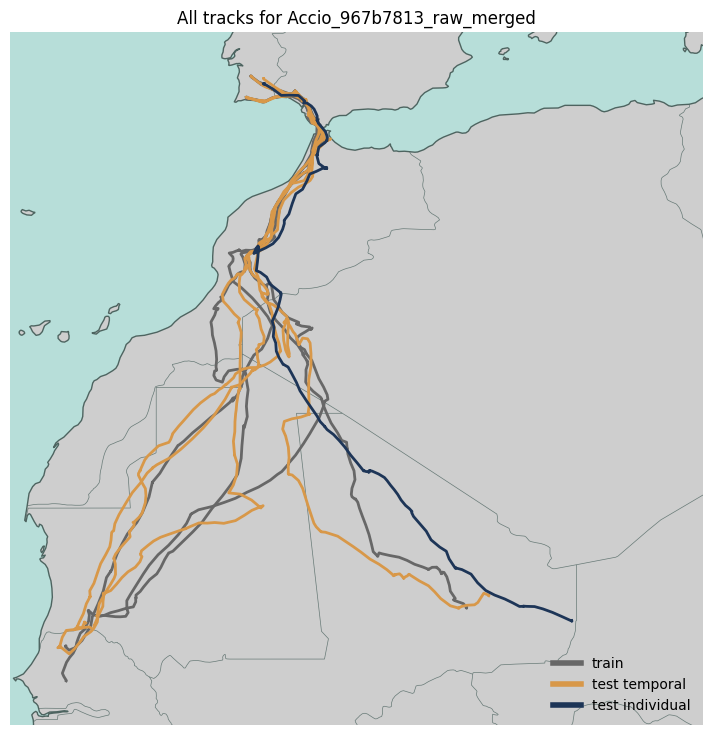

In [14]:
import math

import numpy as np

from movebench.study import Study
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    SET_COL,
    TIME_COL,
    load_trajectories_csv,
)

PLOTTING_INSTALL_CMD = "pip install -e '.[plotting]'"
PLOTTING_AVAILABLE = True
PLOTTING_IMPORT_ERROR = None
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    import matplotlib.pyplot as plt
except Exception as exc:
    PLOTTING_AVAILABLE = False
    PLOTTING_IMPORT_ERROR = exc
    ccrs = None
    cfeature = None
    plt = None

if PLOTTING_AVAILABLE:
    PLATE_CARREE = ccrs.PlateCarree()
    WEB_MERCATOR = ccrs.epsg(3857)
else:
    PLATE_CARREE = None
    WEB_MERCATOR = None

SPLIT_COLORS = {
    "train": "#676767",
    "test_temporal": "#d89849",
    "test_individual": "#1d3557",
}
MAP_OCEAN_COLOR = "#b7ded9"
MAP_LAND_COLOR = "#cecece"
MAP_COASTLINE_COLOR = "#4d6460"


def warn_missing_plotting() -> None:
    print(
        "WARNING: plotting dependencies are not installed. "
        f"Install them with: {PLOTTING_INSTALL_CMD}"
    )
    if PLOTTING_IMPORT_ERROR is not None:
        print(f"Import error: {PLOTTING_IMPORT_ERROR}")


study = Study(STUDY_ID)
traj_df = load_trajectories_csv(study.trajectories_path)

if not PLOTTING_AVAILABLE:
    warn_missing_plotting()
else:
    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={"projection": PLATE_CARREE})
    ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
    ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
    ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
    ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)

    for split_key in ["train", "test_temporal", "test_individual"]:
        split_df = traj_df[traj_df[SET_COL] == split_key]
        if split_df.empty:
            continue
        for _individual_id, track_df in split_df.groupby(INDIVIDUAL_COL, sort=False):
            ordered = track_df.sort_values(TIME_COL)
            ax.plot(
                ordered[LON_COL],
                ordered[LAT_COL],
                color=SPLIT_COLORS[split_key],
                linewidth=2,
                # alpha=0.25,
                transform=PLATE_CARREE,
            )

    lon = traj_df[LON_COL].to_numpy()
    lat = traj_df[LAT_COL].to_numpy()
    lon_pad = max(1.0, 0.08 * (lon.max() - lon.min()))
    lat_pad = max(1.0, 0.08 * (lat.max() - lat.min()))
    ax.set_xlim(lon.min() - lon_pad, lon.max() + lon_pad)
    ax.set_ylim(lat.min() - lat_pad, lat.max() + lat_pad)
    ax.set_box_aspect(1)

    for split_key, color in SPLIT_COLORS.items():
        ax.plot([], [], color=color, linewidth=4, label=split_key.replace("_", " "))

    ax.legend(frameon=False, loc="lower right")
    ax.set_title(f"All tracks for {STUDY_ID}")
    for spine in ax.spines.values():
        spine.set_visible(False)
    plt.show()


## 2. Extract point features

This is the Python equivalent of:

```bash
movebench extract --layers-config configs/layers/lite_12h_12h.yaml --sampler-config configs/samplers/issf_defaults.yaml --studies Accio_967b7813_raw_merged
```


In [ ]:
from movebench.extract import build_extraction_runs, run_extract_job

extract_run = build_extraction_runs(
    layers_configs=[[LAYERS_CONFIG]],
    sampler_configs=[[SAMPLER_CONFIG]],
)[0]
run_extract_job(
    study_id=STUDY_ID,
    run=extract_run,
    n_workers=EXTRACT_WORKERS,
)


## 3. Pack DeepSSF shards

This is the Python equivalent of:

```bash
movebench pack --studies Accio_967b7813_raw_merged --timescales 12h --layers-config configs/layers/lite_12h_12h.yaml
```

It is only needed if you want the `deepssf` run in the benchmark.


In [ ]:
from movebench import pack as pack_runtime

pack_runtime.run_local_pack(
    studies=[STUDY_ID],
    timescales=[TIMESCALE_KEY],
    layers_config=LAYERS_CONFIG,
    splits=None,
    build_workers=PACK_WORKERS,
)


## 4. Run the lite benchmark

This is the Python equivalent of:

```bash
movebench bench run experiments/lite.py --studies Accio_967b7813_raw_merged
```

If you want the `moveformer` run to execute, install the optional `moveformer` extra in the environment first.


In [ ]:
import movebench.bench.run as bench_run

bench_run.run_experiment(
    EXPERIMENT_MODULE,
    studies_override=[STUDY_ID],
)


## 5. Load completed stork runs

The next cell scans the completed runs for the quickstart experiment and builds a compact table of the finished stork results.


In [7]:
import json

import numpy as np
import pandas as pd

import movebench.bench.run as bench_run
import movebench.bench.run_state as bench_run_state

pd.set_option("display.max_columns", 100)

def planned_quickstart_runs() -> list[dict[str, object]]:
    experiment = bench_run.load_experiment(EXPERIMENT_MODULE)
    readiness_map: dict[str, dict[str, object]] = {}
    return [
        dict(run)
        for run in bench_run.expand_experiment(
            experiment,
            studies_override=[STUDY_ID],
            readiness_map=readiness_map,
        )
    ]


def completed_run_inventory() -> pd.DataFrame:
    planned_runs = planned_quickstart_runs()
    latest_records = bench_run_state.search_latest_run_records_by_key(
        [str(run["run_key"]) for run in planned_runs]
    )
    rows: list[dict[str, object]] = []
    for run_payload in planned_runs:
        run_key = str(run_payload["run_key"])
        latest_run = dict(latest_records.get(run_key, {}))
        if str(latest_run.get("status", "")) != "completed":
            continue
        run_dir = RUNS_ROOT / run_key
        for split_key in run_payload.get("evaluation_split_keys", []):
            split_key = str(split_key)
            summary_path = run_dir / "final_metrics" / split_key / "summary.json"
            prediction_path = run_dir / "predictions" / f"{split_key}.pt"
            if not summary_path.exists():
                continue
            summary = json.loads(summary_path.read_text())
            rows.append(
                {
                    "run_key": run_key,
                    "run_dir": run_dir,
                    "study_id": str(run_payload["study_id"]),
                    "timescale": str(run_payload["timescale"]),
                    "covariate_set": str(run_payload["covariate_set"]),
                    "method": str(run_payload["method"]),
                    "split_key": split_key,
                    "energy_score": float(summary["energy_score"]) if summary.get("energy_score") is not None else np.nan,
                    "accuracy": float(summary["accuracy"]) if summary.get("accuracy") is not None else np.nan,
                    "calibration": float(summary["calibration"]) if summary.get("calibration") is not None else np.nan,
                    "n_steps_scored": int(summary["n_steps_scored"]) if summary.get("n_steps_scored") is not None else None,
                    "has_prediction": prediction_path.exists(),
                }
            )
    result_df = pd.DataFrame(rows)
    if result_df.empty:
        return result_df
    result_df["timescale"] = pd.Categorical(result_df["timescale"], TIMESCALE_ORDER, ordered=True)
    return result_df.sort_values(["timescale", "method", "split_key"]).reset_index(drop=True)


results_df = completed_run_inventory()
results_df[[
    "timescale",
    "method",
    "split_key",
    "energy_score",
    "accuracy",
    "calibration",
    "n_steps_scored",
    "has_prediction",
]]


,timescale,method,split_key,energy_score,accuracy,calibration,n_steps_scored,has_prediction
0,12h,baseline_constvel,test_individual,121111.169052,121111.169052,0.000000,241,True
1,12h,baseline_constvel,test_temporal,109571.861927,109571.861927,0.000000,948,True
2,12h,baseline_nomove,test_individual,128598.651187,128598.651187,0.000000,241,True
3,12h,baseline_nomove,test_temporal,116438.298792,116438.298792,0.000000,948,True
4,12h,baseline_randomwalk,test_individual,100917.247943,168103.506623,134372.517359,241,True
5,12h,baseline_randomwalk,test_temporal,91146.230211,158332.470214,134372.480005,948,True
6,12h,issf_linear,test_individual,100040.479588,169649.370591,139217.782005,241,True
7,12h,issf_linear,test_temporal,90573.999600,155471.344212,129794.689224,948,True
8,12h,issf_mlp,test_individual,103769.620045,208986.909039,210434.577988,241,True
9,12h,issf_mlp,test_temporal,94356.655122,194247.964261,199782.618278,948,True


## 6. Stork energy scores

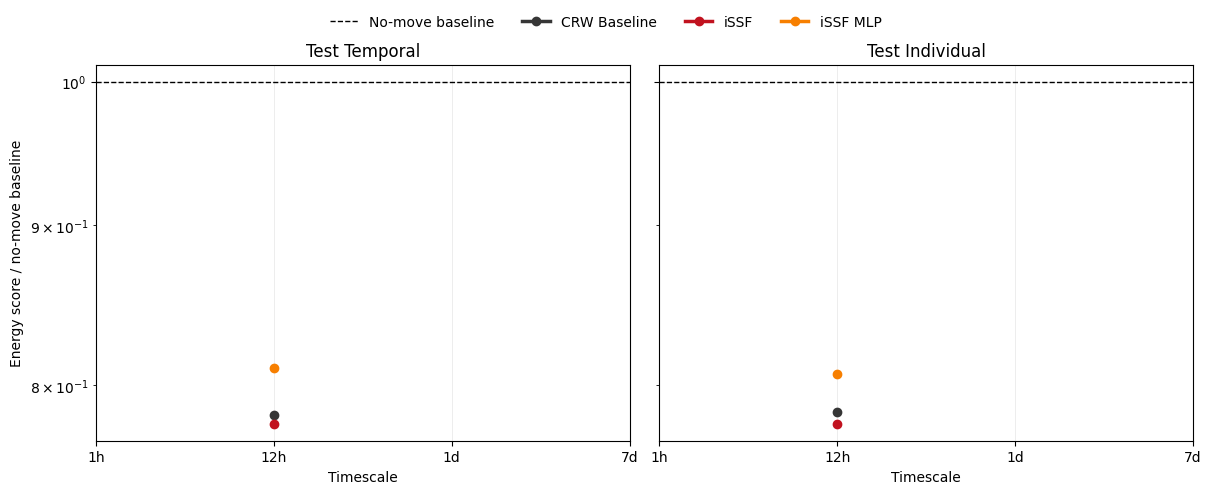

In [12]:
METHOD_LABELS = {
    "baseline_randomwalk": "CRW Baseline",
    "issf_linear": "iSSF",
    "issf_mlp": "iSSF MLP",
    "deepssf": "DeepSSF",
    "moveformer": "MoveFormer",
}
METHOD_COLORS = {
    "baseline_randomwalk": "#363636",
    "issf_linear": "#c1121f",
    "issf_mlp": "#f77f00",
    "deepssf": "#003049",
    "moveformer": "#669bbc",
}


def method_label(method: str) -> str:
    return METHOD_LABELS.get(str(method), str(method))


energy_df = results_df[results_df["method"].isin([NORMALIZE_BY, *PLOT_METHODS])].copy()
baseline_df = energy_df[
    energy_df["method"] == NORMALIZE_BY
][["timescale", "split_key", "energy_score"]].rename(
    columns={"energy_score": "baseline_energy_score"}
)
plot_df = (
    energy_df[energy_df["method"].isin(PLOT_METHODS)]
    .merge(baseline_df, on=["timescale", "split_key"], how="inner", validate="many_to_one")
    .query("baseline_energy_score > 0")
    .copy()
)
plot_df["normalized_energy"] = plot_df["energy_score"] / plot_df["baseline_energy_score"]
plot_df["x"] = plot_df["timescale"].map({key: idx for idx, key in enumerate(TIMESCALE_ORDER)})

if not PLOTTING_AVAILABLE:
    warn_missing_plotting()
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)

    for ax, split_key in zip(axes, SPLIT_ORDER):
        split_df = plot_df[plot_df["split_key"] == split_key]
        ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="No-move baseline")
        for method in PLOT_METHODS:
            method_df = split_df[split_df["method"] == method].sort_values("x")
            if method_df.empty:
                continue
            ax.plot(
                method_df["x"],
                method_df["normalized_energy"],
                marker="o",
                linewidth=2.5,
                color=METHOD_COLORS[method],
                label=method_label(method),
            )
        ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
        ax.set_yscale("log")
        ax.grid(True, linewidth=0.4, alpha=0.4)
        ax.set_title(split_key.replace("_", " ").title())
        ax.set_xlabel("Timescale")

    axes[0].set_ylabel("Energy score / no-move baseline")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", frameon=False, ncol=6, bbox_to_anchor=(0.5, 1.08))
    plt.show()


## 7. Prediction examples


In [9]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from movebench.bench.evaluation import runner as evaluation_runner
from movebench.trajectories import INDIVIDUAL_COL, LAT_COL, LON_COL, TIME_COL

ADVANCED_PLOTTING_AVAILABLE = True
ADVANCED_PLOTTING_IMPORT_ERROR = None
try:
    import rasterio
    from pyproj import Transformer
except Exception as exc:
    ADVANCED_PLOTTING_AVAILABLE = False
    ADVANCED_PLOTTING_IMPORT_ERROR = exc
    rasterio = None
    Transformer = None

if ADVANCED_PLOTTING_AVAILABLE:
    TO_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
    FROM_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)
else:
    TO_3857 = None
    FROM_3857 = None


def warn_missing_advanced_plotting() -> None:
    print(
        "WARNING: plotting dependencies are not installed. "
        f"Install them with: {PLOTTING_INSTALL_CMD}"
    )
    if ADVANCED_PLOTTING_IMPORT_ERROR is not None:
        print(f"Import error: {ADVANCED_PLOTTING_IMPORT_ERROR}")


_trajectory_points_cache: dict[str, pd.DataFrame] = {}
_support_rows_cache: dict[tuple[str, str], tuple[pd.DataFrame, float, dict[str, object]]] = {}
_prediction_artifact_cache: dict[tuple[str, str], dict[str, object]] = {}


def trajectory_points(study_id: str) -> pd.DataFrame:
    if study_id not in _trajectory_points_cache:
        points_df = pd.read_csv(
            paths.study_dir(study_id) / "trajectories.csv",
            usecols=["point_id", LON_COL, LAT_COL, TIME_COL, INDIVIDUAL_COL],
            parse_dates=[TIME_COL],
        ).rename(
            columns={
                "point_id": "point_id_start",
                LON_COL: "lon",
                LAT_COL: "lat",
                INDIVIDUAL_COL: "individual_id",
            }
        )
        points_df["point_id_start"] = points_df["point_id_start"].astype(int)
        _trajectory_points_cache[study_id] = points_df.set_index("point_id_start", drop=False)
    return _trajectory_points_cache[study_id]


def grid_edges_3857(
    start_lon: float,
    start_lat: float,
    pixel_size_m: float,
    shape: tuple[int, int],
) -> tuple[np.ndarray, np.ndarray, float, float]:
    height, width = shape
    x_offsets_m = (
        np.arange(width + 1, dtype=np.float64) - (width // 2) - 0.5
    ) * float(pixel_size_m)
    y_offsets_m = (
        ((height // 2) - np.arange(height + 1, dtype=np.float64)) + 0.5
    ) * float(pixel_size_m)
    start_x_m, start_y_m = TO_3857.transform(float(start_lon), float(start_lat))
    x_edges_m, y_edges_m = np.meshgrid(
        float(start_x_m) + x_offsets_m,
        float(start_y_m) + y_offsets_m,
    )
    return x_edges_m, y_edges_m, float(start_x_m), float(start_y_m)


def load_high_res_rgba(
    study_id: str,
    rasters_hash: str,
    point_id_start: int,
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    raster_root = paths.study_dir(study_id) / "rasters" / rasters_hash
    meta = json.loads((raster_root / "chips_meta.json").read_text())
    band_ids = meta["chip_groups"]["high_res"]["band_ids_in_order"]
    rgb_indexes = [band_ids.index(f"landsat.{band}") + 1 for band in ["red", "green", "blue"]]
    chip_path = raster_root / "chips" / "high_res" / f"{int(point_id_start):05d}.tif"
    with rasterio.open(chip_path) as ds:
        rgb = ds.read(rgb_indexes).astype(np.float32)
        left_x_m, bottom_y_m = TO_3857.transform(float(ds.bounds.left), float(ds.bounds.bottom))
        right_x_m, top_y_m = TO_3857.transform(float(ds.bounds.right), float(ds.bounds.top))
    valid = np.isfinite(rgb) & (rgb > -1000.0)
    valid_px = valid.all(axis=0)
    rgba = np.zeros((*valid_px.shape, 4), dtype=np.float32)
    rgba[..., 3] = valid_px.astype(np.float32)
    rgb_hwc = np.moveaxis(rgb, 0, -1)
    if np.any(valid_px):
        rgb_valid = rgb_hwc[valid_px]
        lo, hi = np.quantile(rgb_valid, [0.02, 0.98])
        scale = max(float(hi - lo), 1e-6)
        rgba[..., :3][valid_px] = np.clip((rgb_valid - float(lo)) / scale, 0.0, 1.0)
        rgba[..., :3] = np.power(rgba[..., :3], 0.85)
    return rgba, (float(left_x_m), float(right_x_m), float(bottom_y_m), float(top_y_m))


def support_rows_for_run(
    run_row: pd.Series,
    split_key: str = "test_temporal",
) -> tuple[pd.DataFrame, float, dict[str, object]]:
    cache_key = (str(run_row["run_key"]), str(split_key))
    if cache_key not in _support_rows_cache:
        run_payload = json.loads((Path(run_row["run_dir"]) / "resolved_run.json").read_text())
        selected_splits = evaluation_runner._selected_splits_for_split(
            run_payload=run_payload,
            split_key=split_key,
        )
        support_rows, buffer_m = evaluation_runner._support_rows_for_split(
            study_id=str(run_row["study_id"]),
            split_key=split_key,
            timescale_key=str(run_row["timescale"]),
            selected_splits=selected_splits,
        )
        support_df = pd.DataFrame(
            {
                "point_id_start": [int(row["point_id_start"]) for row in support_rows],
                "point_id_end": [int(row["point_id_end"]) for row in support_rows],
                "in_support": [bool(row["in_support"]) for row in support_rows],
            }
        )
        _support_rows_cache[cache_key] = (support_df, float(buffer_m), run_payload)
    return _support_rows_cache[cache_key]


def prediction_artifact_for_run(
    run_row: pd.Series,
    split_key: str = "test_temporal",
) -> dict[str, object]:
    cache_key = (str(run_row["run_key"]), str(split_key))
    if cache_key not in _prediction_artifact_cache:
        _prediction_artifact_cache[cache_key] = torch.load(
            Path(run_row["run_dir"]) / "predictions" / f"{split_key}.pt",
            map_location="cpu",
        )
    return _prediction_artifact_cache[cache_key]


def choose_shared_point(run_rows: pd.DataFrame, split_key: str = "test_temporal") -> int:
    candidate_sets: list[set[int]] = []
    in_support_sets: list[set[int]] = []
    for _, run_row in run_rows.iterrows():
        support_df, _buffer_m, _run_payload = support_rows_for_run(run_row, split_key=split_key)
        candidate_sets.append(set(support_df["point_id_start"].tolist()))
        in_support_sets.append(set(support_df.loc[support_df["in_support"], "point_id_start"].tolist()))
    shared_in_support = set.intersection(*in_support_sets) if in_support_sets else set()
    shared_any = set.intersection(*candidate_sets) if candidate_sets else set()
    candidates = sorted(shared_in_support or shared_any)

    # first one ?
    # return int(candidates[len(candidates) // 4])
    return int(candidates[0])


def build_prediction_panel(
    run_row: pd.Series,
    point_id_start: int,
    split_key: str = "test_temporal",
) -> dict[str, object]:
    pred_artifact = prediction_artifact_for_run(run_row, split_key=split_key)
    support_df, buffer_m, run_payload = support_rows_for_run(run_row, split_key=split_key)
    support_row = support_df.loc[support_df["point_id_start"] == int(point_id_start)].iloc[0]
    point_ids = torch.as_tensor(pred_artifact["point_id_start"], dtype=torch.int64)
    idx = int((point_ids == int(point_id_start)).nonzero(as_tuple=True)[0].item())
    scores_hw = torch.as_tensor(pred_artifact["scores"][idx], dtype=torch.float64)
    probs_hw = torch.softmax(scores_hw.reshape(-1), dim=0).reshape(scores_hw.shape).numpy()
    points_df = trajectory_points(str(run_row["study_id"]))
    start_row = points_df.loc[int(point_id_start)]
    end_row = points_df.loc[int(support_row["point_id_end"])]
    x_edges_m, y_edges_m, start_x_m, start_y_m = grid_edges_3857(
        float(start_row["lon"]),
        float(start_row["lat"]),
        float(pred_artifact["pixel_size_m"]),
        tuple(int(v) for v in scores_hw.shape),
    )
    end_x_m, end_y_m = TO_3857.transform(float(end_row["lon"]), float(end_row["lat"]))
    chip_width_m = float(x_edges_m[0, -1] - x_edges_m[0, 0])
    return {
        "study_id": str(run_row["study_id"]),
        "timescale": str(run_row["timescale"]),
        "method": str(run_row["method"]),
        "rasters_hash": str(run_payload["rasters_hash"]),
        "point_id_start": int(point_id_start),
        "point_id_end": int(support_row["point_id_end"]),
        "individual_id": str(start_row["individual_id"]),
        "start_x_m": float(start_x_m),
        "start_y_m": float(start_y_m),
        "end_x_m": float(end_x_m),
        "end_y_m": float(end_y_m),
        "x_edges_m": x_edges_m,
        "y_edges_m": y_edges_m,
        "logp_hw": np.log(np.clip(probs_hw, 1e-12, None)),
        "xlim_m": (float(start_x_m - buffer_m), float(start_x_m + buffer_m)),
        "ylim_m": (float(start_y_m - buffer_m), float(start_y_m + buffer_m)),
        "chip_width_m": chip_width_m,
    }


def latest_prediction_runs(split_key: str = "test_temporal") -> pd.DataFrame:
    prediction_df = results_df[
        results_df["split_key"].eq(split_key)
        & results_df["method"].isin(PLOT_METHODS)
        & results_df["has_prediction"]
    ][["run_key", "run_dir", "study_id", "timescale", "method"]].drop_duplicates()
    if prediction_df.empty:
        return prediction_df
    prediction_df["timescale"] = pd.Categorical(
        prediction_df["timescale"],
        TIMESCALE_ORDER,
        ordered=True,
    )
    return prediction_df.sort_values(["timescale", "method"]).reset_index(drop=True)


In [10]:
prediction_runs_df = latest_prediction_runs()
prediction_runs_df


,run_key,run_dir,study_id,timescale,method
0,study=Accio_967b7813_raw_merged__ts=12h__cov=l...,/Users/justinkay/movebench-may26/results/bench...,Accio_967b7813_raw_merged,12h,baseline_randomwalk
1,study=Accio_967b7813_raw_merged__ts=12h__cov=l...,/Users/justinkay/movebench-may26/results/bench...,Accio_967b7813_raw_merged,12h,issf_linear
2,study=Accio_967b7813_raw_merged__ts=12h__cov=l...,/Users/justinkay/movebench-may26/results/bench...,Accio_967b7813_raw_merged,12h,issf_mlp


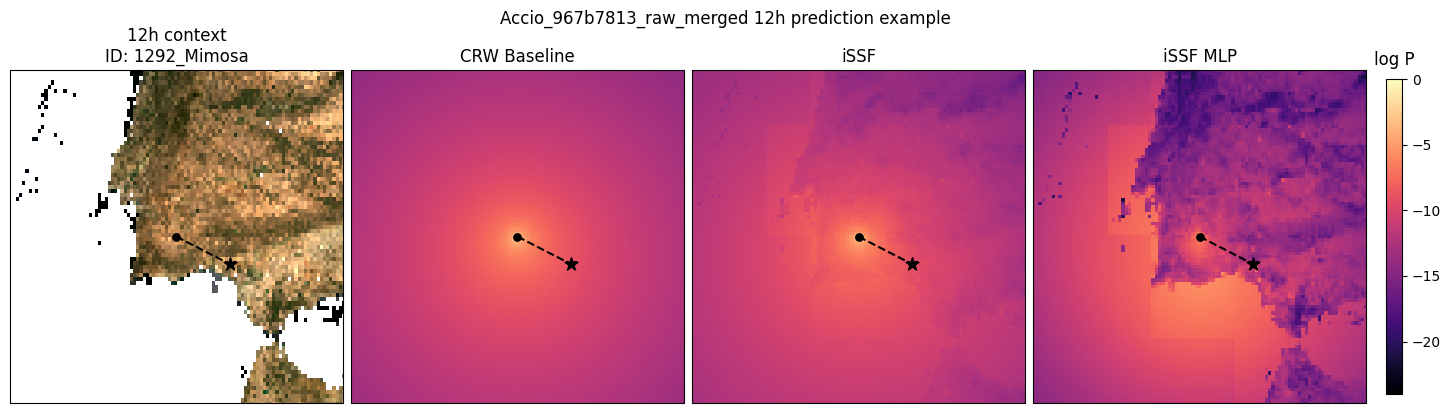

In [ ]:
vmin_logp = -24 # cap minimum log prob for aesthetics

available_timescales = [
    timescale
    for timescale in TIMESCALE_ORDER
    if timescale in set(prediction_runs_df["timescale"].astype(str))
]

if not ADVANCED_PLOTTING_AVAILABLE:
    warn_missing_advanced_plotting()
else:
    for timescale in available_timescales:
        timescale_runs = prediction_runs_df[prediction_runs_df["timescale"].astype(str) == timescale].copy()
        method_order = [method for method in PLOT_METHODS if method in set(timescale_runs["method"])]
        if not method_order:
            continue
        timescale_runs["method"] = pd.Categorical(timescale_runs["method"], method_order, ordered=True)
        timescale_runs = timescale_runs.sort_values("method").reset_index(drop=True)
        point_id_start = choose_shared_point(timescale_runs)
        panels = [build_prediction_panel(run_row, point_id_start) for _, run_row in timescale_runs.iterrows()]
        map_panel = panels[0]
        rgb_rgba, rgb_extent = load_high_res_rgba(
            map_panel["study_id"],
            map_panel["rasters_hash"],
            map_panel["point_id_start"],
        )

        fig, axes = plt.subplots(
            1,
            len(panels) + 1,
            figsize=(3.6 * (len(panels) + 1), 4.2),
            subplot_kw={"projection": WEB_MERCATOR},
            constrained_layout=True,
        )
        axes = np.atleast_1d(axes)

        axes[0].imshow(
            rgb_rgba,
            extent=rgb_extent,
            transform=WEB_MERCATOR,
            interpolation="nearest",
            origin="upper",
            zorder=0,
        )
        axes[0].plot(
            [map_panel["start_x_m"], map_panel["end_x_m"]],
            [map_panel["start_y_m"], map_panel["end_y_m"]],
            color="black",
            linewidth=1.5,
            linestyle="--",
            zorder=1,
            transform=WEB_MERCATOR,
        )
        axes[0].scatter(
            map_panel["start_x_m"],
            map_panel["start_y_m"],
            color="black",
            s=28,
            zorder=2,
            transform=WEB_MERCATOR,
        )
        axes[0].scatter(
            map_panel["end_x_m"],
            map_panel["end_y_m"],
            color="black",
            marker="*",
            s=95,
            zorder=3,
            transform=WEB_MERCATOR,
        )
        axes[0].set_xlim(*map_panel["xlim_m"])
        axes[0].set_ylim(*map_panel["ylim_m"])
        axes[0].set_xticks([])
        axes[0].set_yticks([])
        axes[0].set_title(f"{timescale} context\nID: {map_panel['individual_id']}")

        color_mesh = None
        for ax, panel in zip(axes[1:], panels):
            color_mesh = ax.pcolormesh(
                panel["x_edges_m"],
                panel["y_edges_m"],
                panel["logp_hw"],
                shading="auto",
                cmap="magma",
                vmin=vmin_logp,
                vmax=0.0,
                rasterized=True,
                transform=WEB_MERCATOR,
            )
            ax.plot(
                [panel["start_x_m"], panel["end_x_m"]],
                [panel["start_y_m"], panel["end_y_m"]],
                color="black",
                linewidth=1.5,
                linestyle="--",
                zorder=2,
                transform=WEB_MERCATOR,
            )
            ax.scatter(
                panel["start_x_m"],
                panel["start_y_m"],
                color="black",
                s=28,
                zorder=3,
                transform=WEB_MERCATOR,
            )
            ax.scatter(
                panel["end_x_m"],
                panel["end_y_m"],
                color="black",
                marker="*",
                s=95,
                zorder=4,
                transform=WEB_MERCATOR,
            )
            ax.set_xlim(*panel["xlim_m"])
            ax.set_ylim(*panel["ylim_m"])
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(method_label(panel["method"]))

        cbar = fig.colorbar(color_mesh, ax=axes[1:], shrink=0.78, pad=0.02)
        cbar.ax.set_title("log P", pad=10)
        fig.suptitle(f"{STUDY_ID} {timescale} prediction example", y=1.03)
        plt.show()
